In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()
file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Saving 1776250375-P2-Healthcare Analytics for Doctor Visits (1).csv to 1776250375-P2-Healthcare Analytics for Doctor Visits (1) (1).csv
Dataset loaded successfully!
Dataset shape: (5190, 13)


,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,3,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,4,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,5,1,male,0.19,0.45,2,5,1,no,no,no,yes,no


In [17]:
# STEP 4: Correct data cleaning

df = pd.read_csv(file_name)

df.columns = df.columns.str.strip()

# Remove only the record identifier
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

# Check missing values without deleting records unnecessarily
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

# No missing values in the original uploaded CSV
# Preserve all records for analysis

assert len(df) == 5190, "Check the dataset before proceeding!"

print("\nDataset is ready for analysis.")
display(df.head())

Dataset shape: (5190, 12)

Missing values:
visits       0
gender       0
age          0
income       0
illness      0
reduced      0
health       0
private      0
freepoor     0
freerepat    0
nchronic     0
lchronic     0
dtype: int64

Dataset is ready for analysis.


,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,1,male,0.19,0.45,2,5,1,no,no,no,yes,no


In [18]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all").T)

print("\nDoctor Visit Distribution:")
print(df["visits"].value_counts().sort_index())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   visits     5190 non-null   int64  
 1   gender     5190 non-null   object 
 2   age        5190 non-null   float64
 3   income     5190 non-null   float64
 4   illness    5190 non-null   int64  
 5   reduced    5190 non-null   int64  
 6   health     5190 non-null   int64  
 7   private    5190 non-null   object 
 8   freepoor   5190 non-null   object 
 9   freerepat  5190 non-null   object 
 10  nchronic   5190 non-null   object 
 11  lchronic   5190 non-null   object 
dtypes: float64(2), int64(4), object(6)
memory usage: 486.7+ KB

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
visits,5190.0,NaN,NaN,NaN,0.301734,0.798134,0.0,0.0,0.0,0.0,9.0
gender,5190,2,female,2702,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,5190.0,NaN,NaN,NaN,0.406385,0.204782,0.19,0.22,0.32,0.62,0.72
income,5190.0,NaN,NaN,NaN,0.58316,0.368907,0.0,0.25,0.55,0.9,1.5
illness,5190.0,NaN,NaN,NaN,1.431985,1.384152,0.0,0.0,1.0,2.0,5.0
reduced,5190.0,NaN,NaN,NaN,0.86185,2.887628,0.0,0.0,0.0,0.0,14.0
health,5190.0,NaN,NaN,NaN,1.217534,2.124266,0.0,0.0,0.0,2.0,12.0
private,5190,2,no,2892,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freepoor,5190,2,no,4968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freerepat,5190,2,no,4099,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Doctor Visit Distribution:
visits
0    4141
1     782
2     174
3      30
4      24
5       9
6      12
7      12
8       5
9       1
Name: count, dtype: int64


In [19]:
print("Average doctor visits:", round(df["visits"].mean(), 2))
print("Median doctor visits:", df["visits"].median())
print("Maximum doctor visits:", df["visits"].max())

print("\nAverage visits by gender:")
display(df.groupby("gender")["visits"].mean().reset_index())

print("\nAverage visits by chronic condition:")
display(df.groupby("nchronic")["visits"].mean().reset_index())

print("\nAverage visits by private healthcare:")
display(df.groupby("private")["visits"].mean().reset_index())

Average doctor visits: 0.3
Median doctor visits: 0.0
Maximum doctor visits: 9

Average visits by gender:


,gender,visits
0,female,0.361954
1,male,0.236334



Average visits by chronic condition:


,nchronic,visits
0,no,0.272111
1,yes,0.345602



Average visits by private healthcare:


,private,visits
0,no,0.307400
1,yes,0.294604


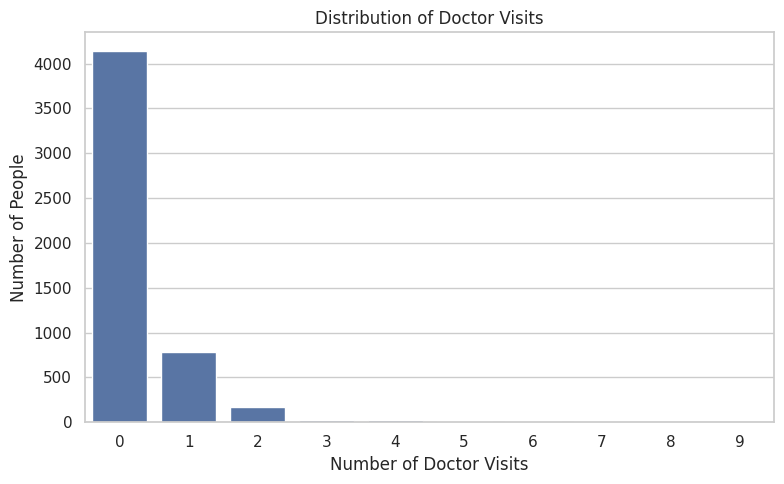

In [20]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="visits")
plt.title("Distribution of Doctor Visits")
plt.xlabel("Number of Doctor Visits")
plt.ylabel("Number of People")
plt.tight_layout()
plt.savefig("doctor_visits_distribution.png", dpi=300)
plt.show()

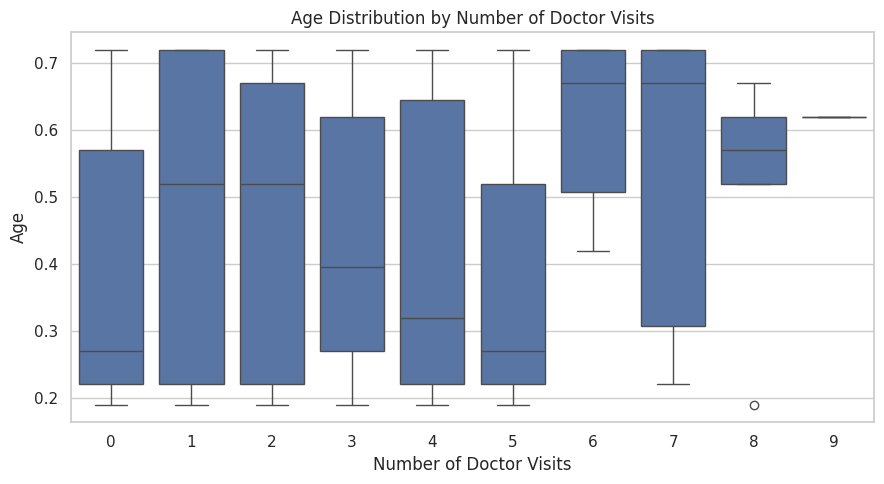

In [21]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="visits", y="age")
plt.title("Age Distribution by Number of Doctor Visits")
plt.xlabel("Number of Doctor Visits")
plt.ylabel("Age")
plt.tight_layout()
plt.savefig("age_vs_visits.png", dpi=300)
plt.show()

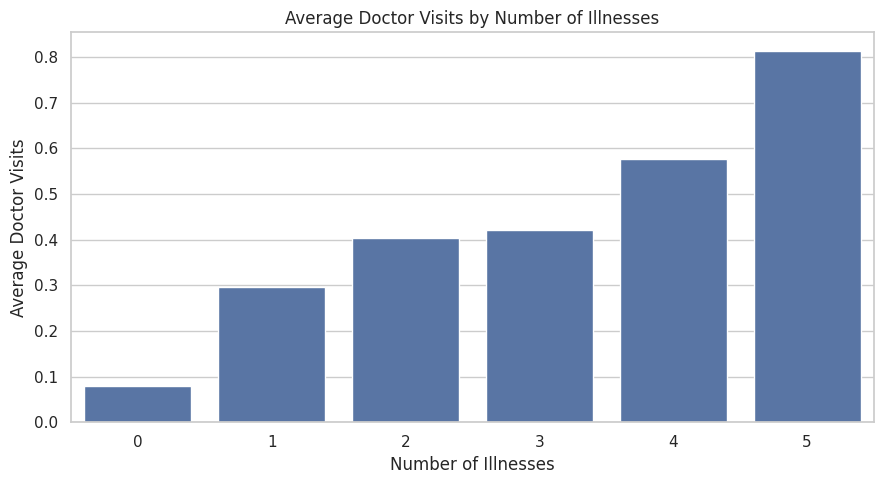

In [22]:
plt.figure(figsize=(9, 5))
sns.barplot(data=df, x="illness", y="visits", errorbar=None)
plt.title("Average Doctor Visits by Number of Illnesses")
plt.xlabel("Number of Illnesses")
plt.ylabel("Average Doctor Visits")
plt.tight_layout()
plt.savefig("illness_vs_visits.png", dpi=300)
plt.show()

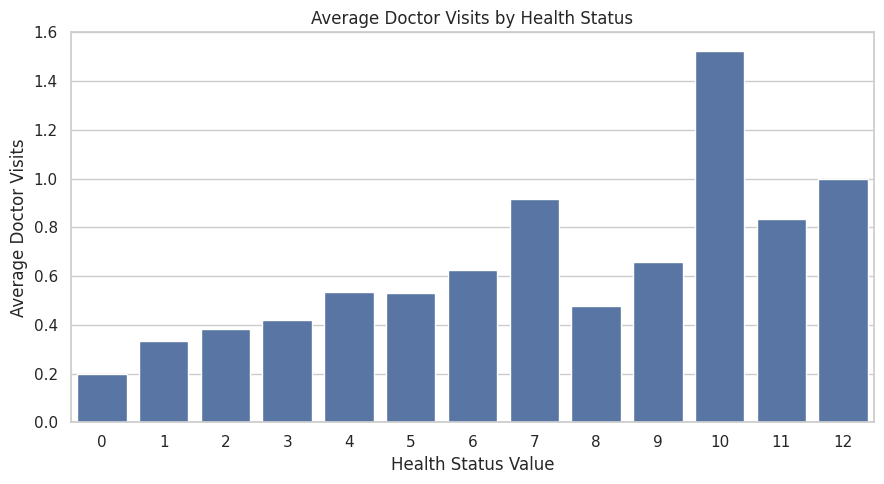

In [23]:
plt.figure(figsize=(9, 5))
sns.barplot(data=df, x="health", y="visits", errorbar=None)
plt.title("Average Doctor Visits by Health Status")
plt.xlabel("Health Status Value")
plt.ylabel("Average Doctor Visits")
plt.tight_layout()
plt.savefig("health_vs_visits.png", dpi=300)
plt.show()

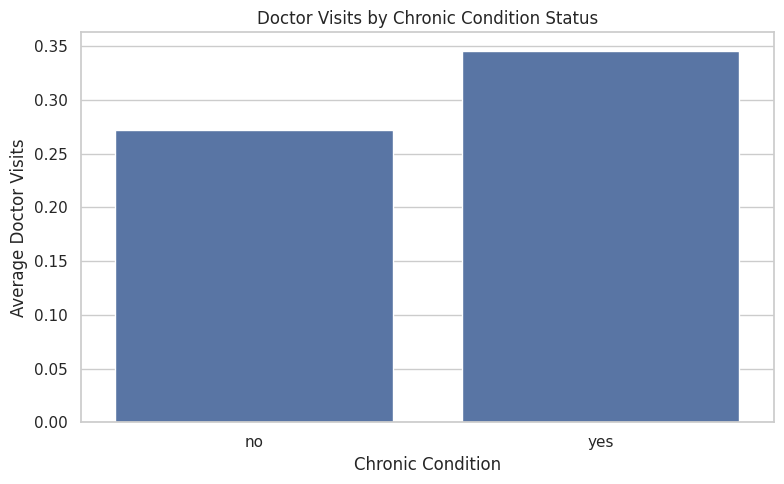

In [24]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="nchronic", y="visits", errorbar=None)
plt.title("Doctor Visits by Chronic Condition Status")
plt.xlabel("Chronic Condition")
plt.ylabel("Average Doctor Visits")
plt.tight_layout()
plt.savefig("chronic_vs_visits.png", dpi=300)
plt.show()

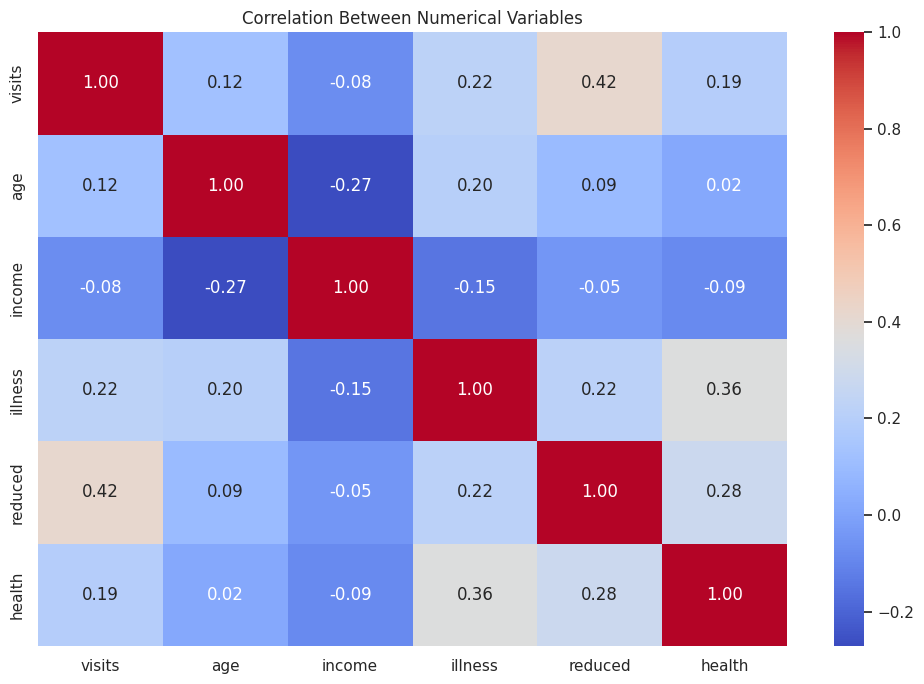

In [25]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=300)
plt.show()

In [26]:
X = df.drop(columns=["visits"])
y = df["visits"]

X = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R²): {r2:.4f}")

MODEL EVALUATION RESULTS
------------------------
Mean Absolute Error (MAE): 0.4383
Root Mean Squared Error (RMSE): 0.8811
R-squared (R²): 0.1221


,Feature,Importance
3,reduced,0.250926
4,health,0.163505
1,income,0.153772
0,age,0.140440
2,illness,0.112529
6,private_yes,0.040145
9,nchronic_yes,0.038387
5,gender_male,0.038188
10,lchronic_yes,0.030719
8,freerepat_yes,0.021037


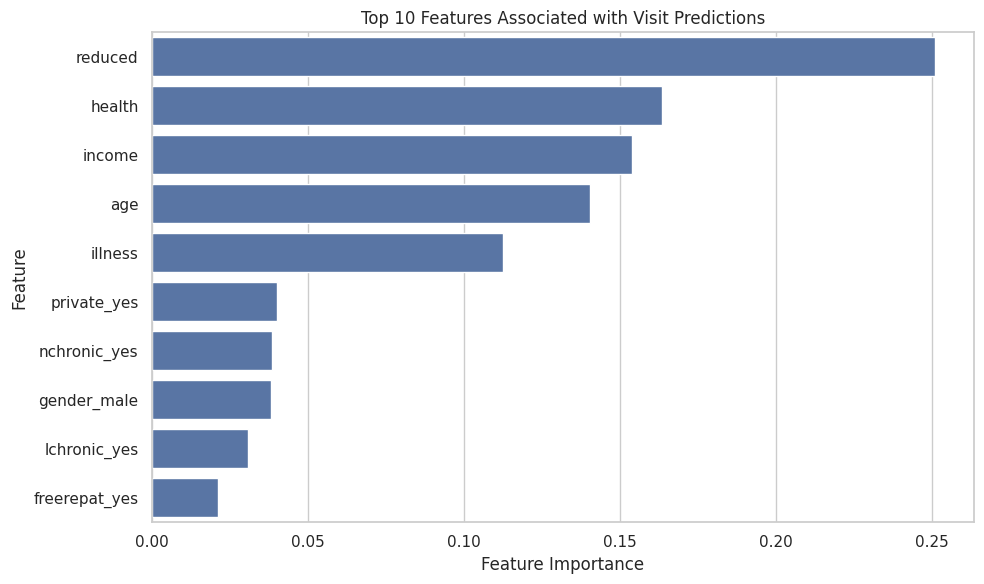

In [27]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance.head(10))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Features Associated with Visit Predictions")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=300)
plt.show()

,Actual Visits,Predicted Visits
0,0,1.025000
1,4,1.145000
2,0,0.650000
3,0,0.072333
4,0,0.035000
5,0,0.008825
6,0,1.019083
7,0,0.073964
8,1,0.135833
9,0,0.490979


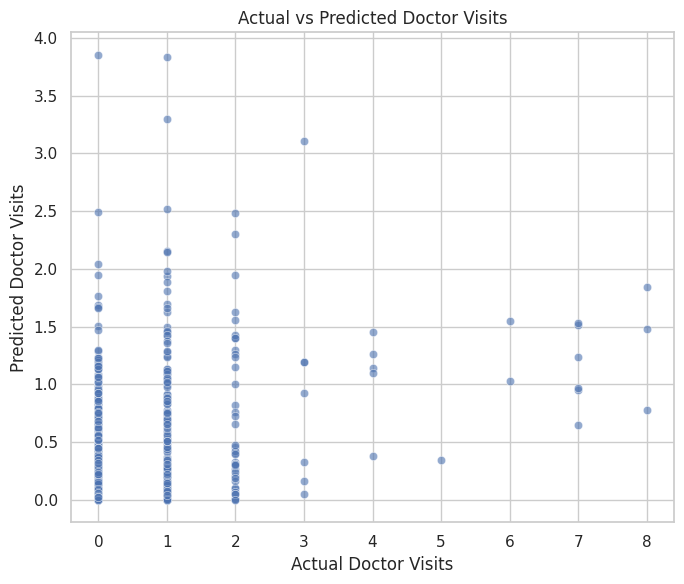

In [28]:
results = pd.DataFrame({
    "Actual Visits": y_test.values,
    "Predicted Visits": y_pred
})

display(results.head(20))

plt.figure(figsize=(7, 6))
sns.scatterplot(
    x=y_test,
    y=y_pred,
    alpha=0.6
)

plt.xlabel("Actual Doctor Visits")
plt.ylabel("Predicted Doctor Visits")
plt.title("Actual vs Predicted Doctor Visits")

plt.tight_layout()
plt.savefig("actual_vs_predicted.png", dpi=300)
plt.show()

In [29]:
findings = []

findings.append(
    f"Total records analyzed: {len(df)}"
)

findings.append(
    f"Average doctor visits: {df['visits'].mean():.2f}"
)

findings.append(
    f"Median doctor visits: {df['visits'].median():.2f}"
)

for col in ["gender", "nchronic", "lchronic",
            "private", "freepoor", "freerepat"]:
    if col in df.columns:
        summary = df.groupby(col)["visits"].mean()
        findings.append(
            f"Average visits by {col}:\n{summary.to_string()}"
        )

findings.append(f"Model MAE: {mae:.4f}")
findings.append(f"Model RMSE: {rmse:.4f}")
findings.append(f"Model R-squared: {r2:.4f}")

with open("project_findings.txt", "w", encoding="utf-8") as f:
    f.write("HEALTHCARE ANALYTICS FOR DOCTOR VISITS\n")
    f.write("=" * 45 + "\n\n")
    f.write("\n\n".join(findings))

print("\n\n".join(findings))
print("\nFindings saved successfully!")

Total records analyzed: 5190

Average doctor visits: 0.30

Median doctor visits: 0.00

Average visits by gender:
gender
female    0.361954
male      0.236334

Average visits by nchronic:
nchronic
no     0.272111
yes    0.345602

Average visits by lchronic:
lchronic
no     0.261941
yes    0.603306

Average visits by private:
private
no     0.307400
yes    0.294604

Average visits by freepoor:
freepoor
no     0.308172
yes    0.157658

Average visits by freerepat:
freerepat
no     0.257868
yes    0.466544

Model MAE: 0.4383

Model RMSE: 0.8811

Model R-squared: 0.1221

Findings saved successfully!


In [30]:
import os
import zipfile

output_files = [
    "doctor_visits_distribution.png",
    "age_vs_visits.png",
    "illness_vs_visits.png",
    "health_vs_visits.png",
    "chronic_vs_visits.png",
    "correlation_heatmap.png",
    "feature_importance.png",
    "actual_vs_predicted.png",
    "project_findings.txt"
]

with zipfile.ZipFile(
    "Healthcare_Analytics_Results.zip", "w"
) as zipf:
    for file in output_files:
        if os.path.exists(file):
            zipf.write(file)

files.download("Healthcare_Analytics_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>